# EVALUATION TABLES AND FIGURES

## Importing Libraries

In [1]:
# Load necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

## Reading Results From File

In [2]:
RESULTS_PATH = "../patient_agent_results/patients_with_system_prompts_without_O/mini agent results.csv"

In [24]:
# Load dataset
df = pd.read_csv(RESULTS_PATH)
df.head()

,id,label,prediction,Module,Tier of Symptom Disclosure,Expected Symptom Direction,Emotion/Tone Tier
0,1,True,True,A - Major Depressive Episode,Tier 1: Superficial/Vague,Positive Symptom Presentation,Flat/Detached
1,2,True,True,A - Major Depressive Episode,Tier 1: Superficial/Vague,Positive Symptom Presentation,Neutral/Cooperative
2,3,True,True,A - Major Depressive Episode,Tier 1: Superficial/Vague,Positive Symptom Presentation,Emotional/Expressive
3,4,False,False,A - Major Depressive Episode,Tier 1: Superficial/Vague,Negative Symptom Presentation,Flat/Detached
4,5,False,False,A - Major Depressive Episode,Tier 1: Superficial/Vague,Negative Symptom Presentation,Neutral/Cooperative


## Basic Data Inspection

In [25]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nFirst few rows:")
print(df.head())
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nUnique values in key columns:")
for col in ['Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']:
    print(f"{col}: {df[col].nunique()} unique values")
    print(f"  {df[col].unique()}")
    print()

Dataset Shape: (210, 7)

Column Names:
['id', 'label', 'prediction', 'Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']

First few rows:
   id  label  prediction                        Module  \
0   1   True        True  A - Major Depressive Episode   
1   2   True        True  A - Major Depressive Episode   
2   3   True        True  A - Major Depressive Episode   
3   4  False       False  A - Major Depressive Episode   
4   5  False       False  A - Major Depressive Episode   

  Tier of Symptom Disclosure     Expected Symptom Direction  \
0  Tier 1: Superficial/Vague  Positive Symptom Presentation   
1  Tier 1: Superficial/Vague  Positive Symptom Presentation   
2  Tier 1: Superficial/Vague  Positive Symptom Presentation   
3  Tier 1: Superficial/Vague  Negative Symptom Presentation   
4  Tier 1: Superficial/Vague  Negative Symptom Presentation   

      Emotion/Tone Tier  
0         Flat/Detached  
1   Neutral/Cooperative  
2  Emotional/Expr

## Classification Metrics

In [26]:
# Calculate basic classification metrics
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score

# Convert boolean values to integers for easier calculation
y_true = df['label'].astype(int)
y_pred = df['prediction'].astype(int)

# Calculate confusion matrix components
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print results
print("=== CONFUSION MATRIX COMPONENTS ===")
print(f"True Positives (TP):  {tp}")
print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Total Samples: {tp + tn + fp + fn}")

print("\n=== PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-Score:  {f1:.4f} ({f1*100:.2f}%)")

# Create a summary dataframe
metrics_summary = pd.DataFrame({
    'Metric': ['TP', 'TN', 'FP', 'FN', 'Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [tp, tn, fp, fn, accuracy, precision, recall, f1],
    'Percentage': [f"{tp/(tp+tn+fp+fn)*100:.2f}%",
                   f"{tn/(tp+tn+fp+fn)*100:.2f}%",
                   f"{fp/(tp+tn+fp+fn)*100:.2f}%",
                   f"{fn/(tp+tn+fp+fn)*100:.2f}%",
                   f"{accuracy*100:.2f}%",
                   f"{precision*100:.2f}%",
                   f"{recall*100:.2f}%",
                   f"{f1*100:.2f}%"]
})

print("\n=== METRICS SUMMARY TABLE ===")
print(metrics_summary)

=== CONFUSION MATRIX COMPONENTS ===
True Positives (TP):  96
True Negatives (TN):  105
False Positives (FP): 0
False Negatives (FN): 9
Total Samples: 210

=== PERFORMANCE METRICS ===
Accuracy:  0.9571 (95.71%)
Precision: 1.0000 (100.00%)
Recall:    0.9143 (91.43%)
F1-Score:  0.9552 (95.52%)

=== METRICS SUMMARY TABLE ===
      Metric       Value Percentage
0         TP   96.000000     45.71%
1         TN  105.000000     50.00%
2         FP    0.000000      0.00%
3         FN    9.000000      4.29%
4   Accuracy    0.957143     95.71%
5  Precision    1.000000    100.00%
6     Recall    0.914286     91.43%
7   F1-Score    0.955224     95.52%


## Modules and Tiers

F1 Score Matrix (Modules × Tiers)
                                     Tier 1: Superficial/Vague  \
A - Major Depressive Episode                               1.0   
D - Panic Disorder                                         1.0   
E - Agoraphobia                                            1.0   
F - Social Anxiety Disorder                                1.0   
G - Obsessive-Compulsive Disorder                          1.0   
N - Generalized Anxiety Disorder                           0.8   
P - Antisocial Personality Disorder                        1.0   

                                     Tier 2: Basic with Minimal Detail  \
A - Major Depressive Episode                                       1.0   
D - Panic Disorder                                                 1.0   
E - Agoraphobia                                                    1.0   
F - Social Anxiety Disorder                                        1.0   
G - Obsessive-Compulsive Disorder                                  

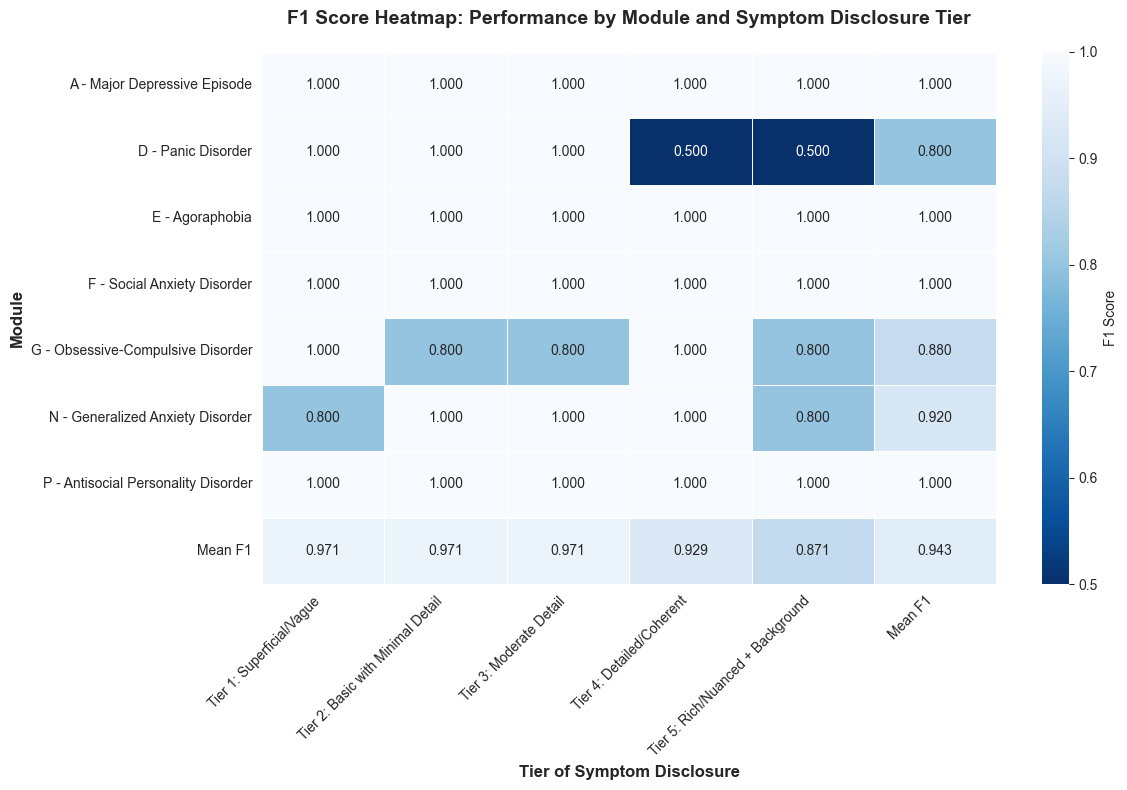


Matrix also saved as 'f1_scores_by_module_tier' for further analysis


In [44]:
# Create F1 score matrix: rows = Module, columns = Tier of Symptom Disclosure
from sklearn.metrics import f1_score
import pandas as pd

# Convert boolean values to integers
df['label_int'] = df['label'].astype(int)
df['prediction_int'] = df['prediction'].astype(int)

# Get unique modules and tiers
modules = df['Module'].unique()
tiers = df['Tier of Symptom Disclosure'].unique()

# Initialize the F1 score matrix
f1_matrix = pd.DataFrame(index=modules, columns=tiers)

# Calculate F1 score for each Module-Tier combination
for module in modules:
    for tier in tiers:
        # Filter data for specific module and tier
        subset = df[(df['Module'] == module) & (df['Tier of Symptom Disclosure'] == tier)]

        if len(subset) > 0:
            # Check if we have both classes in this subset
            if len(subset['label_int'].unique()) > 1:
                f1 = f1_score(subset['label_int'], subset['prediction_int'])
                f1_matrix.loc[module, tier] = f1
            else:
                # If only one class present, check if predictions are correct
                if (subset['label_int'] == subset['prediction_int']).all():
                    f1_matrix.loc[module, tier] = 1.0  # Perfect score
                else:
                    f1_matrix.loc[module, tier] = 0.0  # All wrong
        else:
            f1_matrix.loc[module, tier] = None

# Convert to float and round to 4 decimal places
f1_matrix = f1_matrix.astype(float).round(4)

print("F1 Score Matrix (Modules × Tiers)")
print("=" * 50)
print(f1_matrix)

# Print summary statistics
print("\n" + "=" * 50)
print("SUMMARY STATISTICS")
print("=" * 50)
print(f"Overall mean F1: {f1_matrix.mean().mean():.4f}")
print(f"Best performing combination: {f1_matrix.max().max():.4f}")
print(f"Worst performing combination: {f1_matrix.min().min():.4f}")

# Find best and worst performing combinations
max_val = f1_matrix.max().max()
min_val = f1_matrix.min().min()

best_positions = f1_matrix.stack().idxmax()
worst_positions = f1_matrix.stack().idxmin()

print(f"\nBest: {best_positions[0]} × {best_positions[1]} = {max_val:.4f}")
print(f"Worst: {worst_positions[0]} × {worst_positions[1]} = {min_val:.4f}")

# Save the matrix for further use
f1_scores_by_module_symptom = f1_matrix.copy()

# Create heatmap visualization
plt.figure(figsize=(12, 8))
f1_matrix['Mean F1'] = f1_matrix.mean(axis=1, skipna=True)
mean_row = f1_matrix.mean(axis=0, skipna=True)
mean_row.name = 'Mean F1'
f1_matrix = pd.concat([f1_matrix, mean_row.to_frame().T])

sns.heatmap(f1_matrix,
            annot=True,           # Show values in cells
            cmap='Blues_r',      # Color scheme (red-yellow-blue reversed)
            fmt='.3f',            # Format numbers to 3 decimal places
            cbar_kws={'label': 'F1 Score'},
            linewidths=0.5,       # Add grid lines
            square=False)         # Don't force square cells

plt.title('F1 Score Heatmap: Performance by Module and Symptom Disclosure Tier',
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Tier of Symptom Disclosure', fontsize=12, fontweight='bold')
plt.ylabel('Module', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nMatrix also saved as 'f1_scores_by_module_tier' for further analysis")

In [31]:
f1_scores_by_module_symptom

,Tier 1: Superficial/Vague,Tier 2: Basic with Minimal Detail,Tier 3: Moderate Detail,Tier 4: Detailed/Coherent,Tier 5: Rich/Nuanced + Background
A - Major Depressive Episode,1.0,1.0,1.0,1.0,1.0
D - Panic Disorder,1.0,1.0,1.0,0.5,0.5
E - Agoraphobia,1.0,1.0,1.0,1.0,1.0
F - Social Anxiety Disorder,1.0,1.0,1.0,1.0,1.0
G - Obsessive-Compulsive Disorder,1.0,0.8,0.8,1.0,0.8
N - Generalized Anxiety Disorder,0.8,1.0,1.0,1.0,0.8
P - Antisocial Personality Disorder,1.0,1.0,1.0,1.0,1.0


## Module and Symptom

F1 Score Matrix (Modules × Expected Symptom Direction)
                                     Negative Symptom Presentation  \
A - Major Depressive Episode                                   1.0   
D - Panic Disorder                                             1.0   
E - Agoraphobia                                                1.0   
F - Social Anxiety Disorder                                    1.0   
G - Obsessive-Compulsive Disorder                              1.0   
N - Generalized Anxiety Disorder                               1.0   
P - Antisocial Personality Disorder                            1.0   

                                     Positive Symptom Presentation  
A - Major Depressive Episode                                1.0000  
D - Panic Disorder                                          0.4231  
E - Agoraphobia                                             1.0000  
F - Social Anxiety Disorder                                 1.0000  
G - Obsessive-Compulsive Disorder      

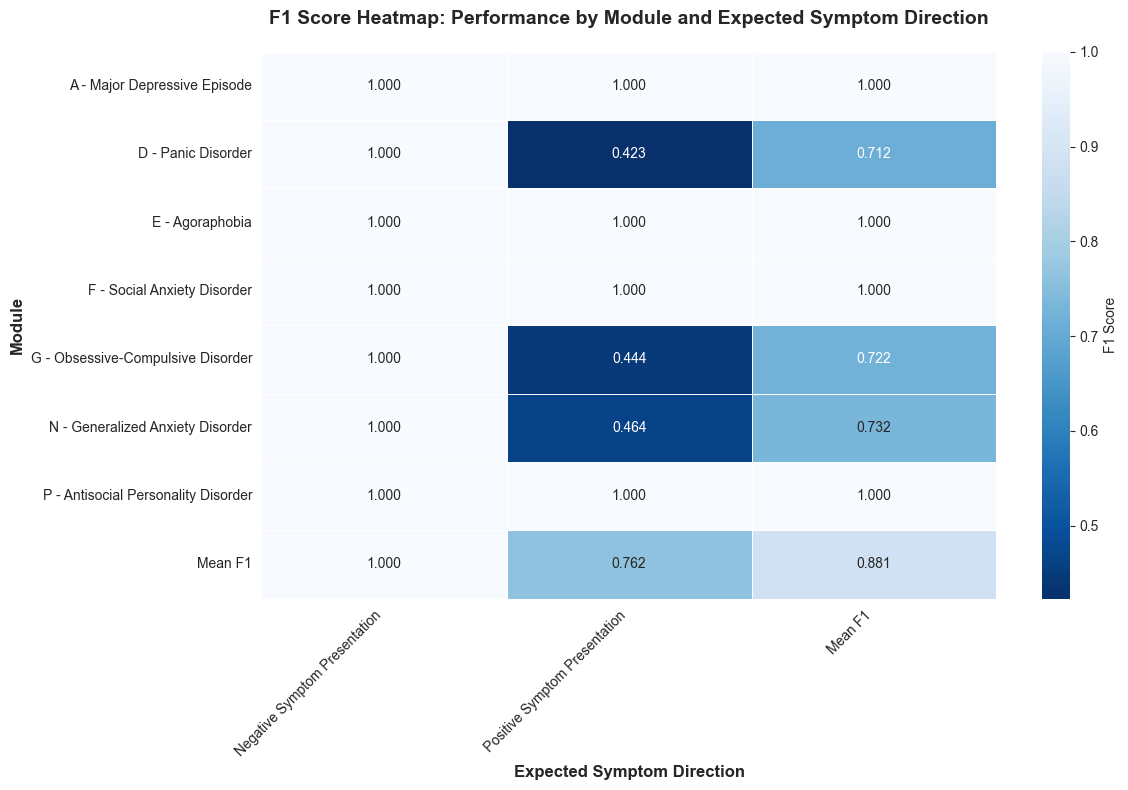

In [43]:
# 1) Normalize labels to 0/1
map_bool = {'yes': 1, 'no': 0, True: 1, False: 0, 1: 1, 0: 0}
work = df.copy()

work['label_int'] = work['label'].map(map_bool)
work['prediction_int'] = work['prediction'].map(map_bool)

# Guard against unmapped values
if work[['label_int', 'prediction_int']].isna().any().any():
    raise ValueError("Unmapped values found in label or prediction columns.")

# 2) Optional: drop rows with missing keys
key_cols = ['Module', 'Expected Symptom Direction', 'label_int', 'prediction_int']
work = work.dropna(subset=key_cols)

modules = sorted(work['Module'].unique())
directions = sorted(work['Expected Symptom Direction'].unique())

f1_matrix = pd.DataFrame(index=modules, columns=directions, dtype=float)

# 3) Compute F1 robustly
for module in modules:
    for direction in directions:
        subset = work[(work['Module'] == module) &
                      (work['Expected Symptom Direction'] == direction)]
        if subset.empty:
            f1_matrix.loc[module, direction] = np.nan
            continue

        y_true = subset['label_int'].to_numpy()
        y_pred = subset['prediction_int'].to_numpy()

        # Option A: standard binary F1 for positive class 1
        # f1 = f1_score(y_true, y_pred, zero_division=0)

        # Option B: macro F1 to handle single-class true labels without hacks
        f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

        f1_matrix.loc[module, direction] = f1

# 4) Summaries with guards
overall_mean = f1_matrix.values[np.isfinite(f1_matrix.values)].mean() if np.isfinite(f1_matrix.values).any() else np.nan

print("F1 Score Matrix (Modules × Expected Symptom Direction)")
print("=" * 50)
print(f1_matrix.round(4))

print("\n" + "=" * 50)
print("SUMMARY STATISTICS")
print("=" * 50)
print(f"Overall mean F1: {overall_mean:.4f}" if np.isfinite(overall_mean) else "Overall mean F1: n/a")

stacked = f1_matrix.stack()
if stacked.empty:
    print("No valid F1 scores to summarize.")
else:
    max_pos = stacked.idxmax()
    min_pos = stacked.idxmin()
    print(f"Best performing combination: {stacked[max_pos]:.4f} at {max_pos[0]} × {max_pos[1]}")
    print(f"Worst performing combination: {stacked[min_pos]:.4f} at {min_pos[0]} × {min_pos[1]}")

# 5) Heatmap
plt.figure(figsize=(12, 8))
f1_matrix['Mean F1'] = f1_matrix.mean(axis=1, skipna=True)
mean_row = f1_matrix.mean(axis=0, skipna=True)
mean_row.name = 'Mean F1'
f1_matrix = pd.concat([f1_matrix, mean_row.to_frame().T])

sns.heatmap(f1_matrix.round(3),
            annot=True,
            cmap='Blues_r',
            fmt='.3f',
            cbar_kws={'label': 'F1 Score'},
            linewidths=0.5)
plt.title('F1 Score Heatmap: Performance by Module and Expected Symptom Direction', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Expected Symptom Direction', fontsize=12, fontweight='bold')
plt.ylabel('Module', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


F1 Score Matrix (Modules × Emotion/Tone Tier)
                                     Emotional/Expressive  Flat/Detached  \
A - Major Depressive Episode                       1.0000            1.0   
D - Panic Disorder                                 0.7917            1.0   
E - Agoraphobia                                    1.0000            1.0   
F - Social Anxiety Disorder                        1.0000            1.0   
G - Obsessive-Compulsive Disorder                  0.7917            1.0   
N - Generalized Anxiety Disorder                   0.7917            1.0   
P - Antisocial Personality Disorder                1.0000            1.0   

                                     Neutral/Cooperative  
A - Major Depressive Episode                      1.0000  
D - Panic Disorder                                0.7917  
E - Agoraphobia                                   1.0000  
F - Social Anxiety Disorder                       1.0000  
G - Obsessive-Compulsive Disorder                 

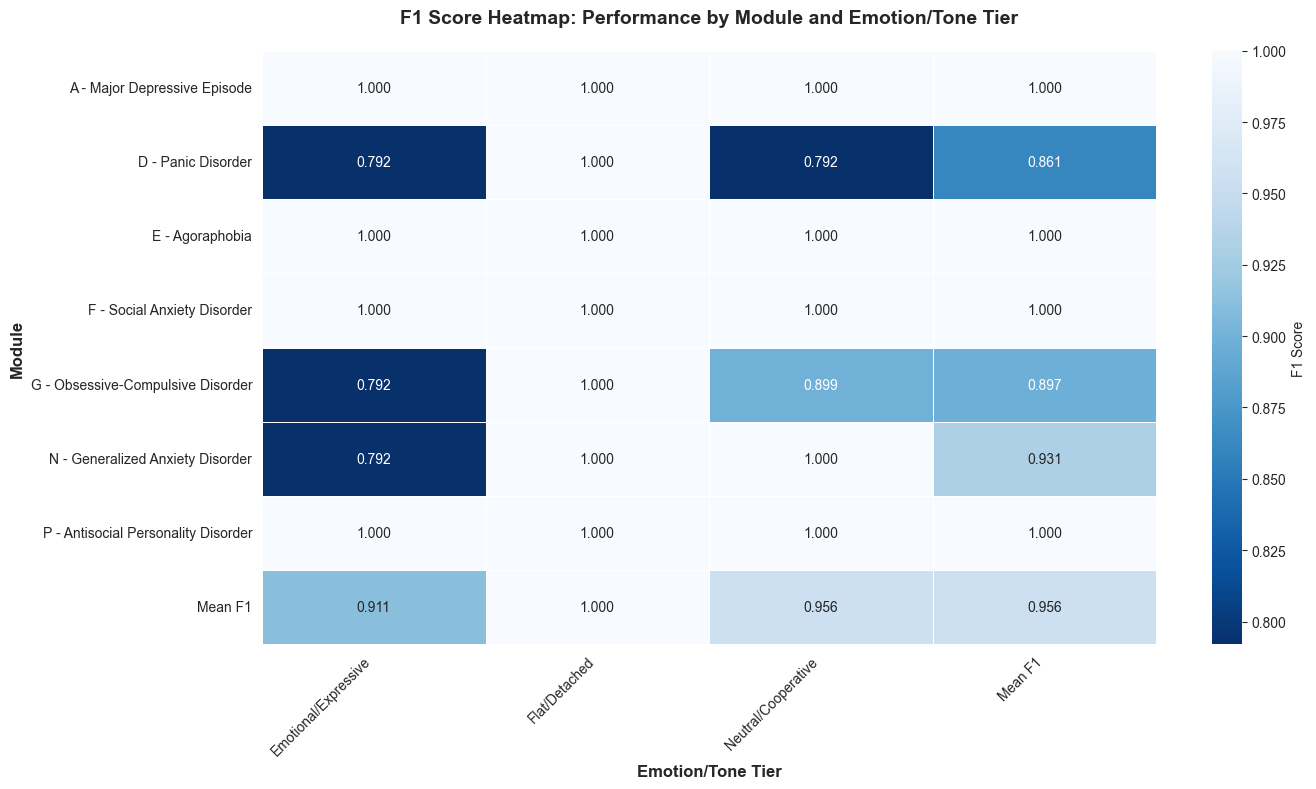

In [42]:
# 1) Normalize labels to 0/1
map_bool = {'yes': 1, 'no': 0, True: 1, False: 0, 1: 1, 0: 0}
work = df.copy()
work['label_int'] = work['label'].map(map_bool)
work['prediction_int'] = work['prediction'].map(map_bool)

# Guard against unmapped values
if work[['label_int', 'prediction_int']].isna().any().any():
    raise ValueError("Unmapped values found in label or prediction columns.")

# 2) Optional: drop rows with missing keys
key_cols = ['Module', 'Emotion/Tone Tier', 'label_int', 'prediction_int']
work = work.dropna(subset=key_cols)

modules = sorted(work['Module'].unique())
tones = sorted(work['Emotion/Tone Tier'].unique())
f1_matrix = pd.DataFrame(index=modules, columns=tones, dtype=float)

# 3) Compute F1 robustly
for module in modules:
    for tone in tones:
        subset = work[(work['Module'] == module) &
                      (work['Emotion/Tone Tier'] == tone)]
        if subset.empty:
            f1_matrix.loc[module, tone] = np.nan
            continue

        y_true = subset['label_int'].to_numpy()
        y_pred = subset['prediction_int'].to_numpy()

        # Option A: standard binary F1 for positive class 1
        # f1 = f1_score(y_true, y_pred, zero_division=0)
        # Option B: macro F1 to handle single-class true labels without hacks
        f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
        f1_matrix.loc[module, tone] = f1

# 4) Summaries with guards
overall_mean = f1_matrix.values[np.isfinite(f1_matrix.values)].mean() if np.isfinite(f1_matrix.values).any() else np.nan

print("F1 Score Matrix (Modules × Emotion/Tone Tier)")
print("=" * 50)
print(f1_matrix.round(4))

print("\n" + "=" * 50)
print("SUMMARY STATISTICS")
print("=" * 50)
print(f"Overall mean F1: {overall_mean:.4f}" if np.isfinite(overall_mean) else "Overall mean F1: n/a")

stacked = f1_matrix.stack()
if stacked.empty:
    print("No valid F1 scores to summarize.")
else:
    max_pos = stacked.idxmax()
    min_pos = stacked.idxmin()
    print(f"Best performing combination: {stacked[max_pos]:.4f} at {max_pos[0]} × {max_pos[1]}")
    print(f"Worst performing combination: {stacked[min_pos]:.4f} at {min_pos[0]} × {min_pos[1]}")

# 5) Heatmap (including the Mean F1 column)
plt.figure(figsize=(14, 8))
f1_matrix['Mean F1'] = f1_matrix.mean(axis=1, skipna=True)
mean_row = f1_matrix.mean(axis=0, skipna=True)
mean_row.name = 'Mean F1'
f1_matrix = pd.concat([f1_matrix, mean_row.to_frame().T])


sns.heatmap(f1_matrix.round(3),
            annot=True,
            cmap='Blues_r',
            fmt='.3f',
            cbar_kws={'label': 'F1 Score'},
            linewidths=0.5)

plt.title('F1 Score Heatmap: Performance by Module and Emotion/Tone Tier',
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Emotion/Tone Tier', fontsize=12, fontweight='bold')
plt.ylabel('Module', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Add a cumulative column (mean F1 across all tones for each module)

# Save the matrix for further use
f1_scores_by_module_tone = f1_matrix.copy()

In [3]:
# EVALUATION TABLES AND FIGURES

# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Configuration
RESULTS_PATH = "../patient_agent_results/patients_with_system_prompts_without_O/mini agent results.csv"

In [5]:
def load_and_inspect_data(filepath):
    """Load and perform basic inspection of the dataset."""
    df = pd.read_csv(filepath)

    print("Dataset Shape:", df.shape)
    print("\nColumn Names:")
    print(df.columns.tolist())
    print("\nFirst few rows:")
    print(df.head())
    print("\nData Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nUnique values in key columns:")

    key_columns = ['Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']
    for col in key_columns:
        if col in df.columns:
            print(f"{col}: {df[col].nunique()} unique values")
            print(f"  {df[col].unique()}")
            print()

    return df


In [6]:
def normalize_labels(df):
    """Normalize labels to consistent 0/1 format."""
    df_work = df.copy()
    label_map = {'yes': 1, 'no': 0, True: 1, False: 0, 1: 1, 0: 0}

    df_work['label_int'] = df_work['label'].map(label_map)
    df_work['prediction_int'] = df_work['prediction'].map(label_map)

    # Handle unmapped values
    if df_work[['label_int', 'prediction_int']].isna().any().any():
        print("Warning: Some labels could not be mapped. Filling with original values.")
        df_work['label_int'] = df_work['label_int'].fillna(df_work['label'].astype(int))
        df_work['prediction_int'] = df_work['prediction_int'].fillna(df_work['prediction'].astype(int))

    return df_work


In [7]:
def calculate_basic_metrics(df):
    """Calculate and display basic classification metrics."""
    y_true = df['label_int'].astype(int)
    y_pred = df['prediction_int'].astype(int)

    # Calculate confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Calculate metrics
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }

    # Display results
    print("=== CONFUSION MATRIX COMPONENTS ===")
    print(f"True Positives (TP):  {tp}")
    print(f"True Negatives (TN):  {tn}")
    print(f"False Positives (FP): {fp}")
    print(f"False Negatives (FN): {fn}")
    print(f"Total Samples: {tp + tn + fp + fn}")

    print("\n=== PERFORMANCE METRICS ===")
    for metric_name, value in metrics.items():
        print(f"{metric_name.capitalize():10}: {value:.4f} ({value*100:.2f}%)")

    # Create summary table
    metrics_summary = pd.DataFrame({
        'Metric': ['TP', 'TN', 'FP', 'FN'] + list(metrics.keys()),
        'Value': [tp, tn, fp, fn] + list(metrics.values()),
        'Percentage': [f"{x/(tp+tn+fp+fn)*100:.2f}%" for x in [tp, tn, fp, fn]] +
                     [f"{v*100:.2f}%" for v in metrics.values()]
    })

    print("\n=== METRICS SUMMARY TABLE ===")
    print(metrics_summary)

    return metrics_summary




In [8]:
def create_metric_matrix(df, row_col, col_col, title_suffix, metric='f1'):
    """
    Create metric score matrix for two categorical variables.

    Args:
        df: DataFrame with normalized labels
        row_col: Column name for matrix rows
        col_col: Column name for matrix columns
        title_suffix: Suffix for plot title
        metric: 'f1' or 'accuracy'
    """
    # Ensure required columns exist
    required_cols = [row_col, col_col, 'label_int', 'prediction_int']
    df_clean = df.dropna(subset=required_cols)

    if df_clean.empty:
        print(f"No data available for {row_col} × {col_col} analysis")
        return None

    # Get unique values
    rows = sorted(df_clean[row_col].unique())
    cols = sorted(df_clean[col_col].unique())

    # Initialize matrix
    metric_matrix = pd.DataFrame(index=rows, columns=cols, dtype=float)

    # Calculate metric scores
    for row_val in rows:
        for col_val in cols:
            subset = df_clean[
                (df_clean[row_col] == row_val) &
                (df_clean[col_col] == col_val)
            ]

            if subset.empty:
                metric_matrix.loc[row_val, col_val] = np.nan
                continue

            y_true = subset['label_int'].to_numpy()
            y_pred = subset['prediction_int'].to_numpy()

            # Calculate metric
            if metric == 'f1':
                score = f1_score(y_true, y_pred, average='macro', zero_division=0)
            elif metric == 'accuracy':
                score = accuracy_score(y_true, y_pred)
            else:
                raise ValueError(f"Unsupported metric: {metric}")

            metric_matrix.loc[row_val, col_val] = score

    # Display results
    metric_name = metric.upper()
    print(f"{metric_name} Score Matrix ({row_col} × {col_col})")
    print("=" * 50)
    print(metric_matrix.round(4))

    # Summary statistics
    finite_values = metric_matrix.values[np.isfinite(metric_matrix.values)]
    if len(finite_values) > 0:
        overall_mean = finite_values.mean()
        print(f"\nOverall mean {metric_name}: {overall_mean:.4f}")

        stacked = metric_matrix.stack()
        max_pos = stacked.idxmax()
        min_pos = stacked.idxmin()
        print(f"Best: {max_pos[0]} × {max_pos[1]} = {stacked[max_pos]:.4f}")
        print(f"Worst: {min_pos[0]} × {min_pos[1]} = {stacked[min_pos]:.4f}")

    # Create heatmap
    plot_metric_heatmap(metric_matrix, row_col, col_col, title_suffix, metric)

    return metric_matrix



In [13]:
def plot_metric_heatmap(metric_matrix, row_label, col_label, title_suffix, metric='f1'):
    """Create and display metric score heatmap with consistent formatting."""
    # Add mean columns and rows
    metric_plot = metric_matrix.copy()
    metric_plot['Mean'] = metric_plot.mean(axis=1, skipna=True)
    mean_row = metric_plot.mean(axis=0, skipna=True)
    mean_row.name = 'Mean'
    metric_plot = pd.concat([metric_plot, mean_row.to_frame().T])

    # Calculate consistent figure size based on matrix dimensions
    n_cols = len(metric_plot.columns)
    n_rows = len(metric_plot.index)
    fig_width = max(8, n_cols * 0.8)  # Minimum width 8, scale with columns
    fig_height = max(5, n_rows * 0.6)  # Minimum height 5, scale with rows

    # Create plot with consistent sizing
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Set font to Arial globally
    plt.rcParams['font.family'] = 'Arial'
    plt.rcParams['font.size'] = 10

    # Create custom colormap from light blue (0.4) to darker blue (1.0)
    from matplotlib.colors import LinearSegmentedColormap
    blues_custom = plt.cm.Blues(np.linspace(0.3, 0.9, 256))  # Light blue to readable dark blue
    custom_cmap = LinearSegmentedColormap.from_list('custom_blues', blues_custom)

    sns.heatmap(
        metric_plot,
        annot=True,
        cmap=custom_cmap,
        fmt='.2f',  # Two digits after decimal
        vmin=0.00,  # Min value 0.40 for consistent range
        vmax=1.00,  # Max value 1.00
        cbar_kws={
            'label': f'{metric.upper()} Score',
            'shrink': 0.8  # Smaller colorbar
        },
        linewidths=0.2,  # Very thin lines for condensed look
        linecolor='white',
        square=True,  # Square cells for consistency
        ax=ax,
        annot_kws={
            'fontsize': 10,
            'fontfamily': 'Arial',
            'fontweight': 'bold'  # Bold numbers for better readability
        }
    )

    # Formatting with Arial font
    metric_name = metric.upper()
    ax.set_title(f'{metric_name} Score: {title_suffix}',
                fontsize=10, fontweight='bold', pad=10, fontfamily='Arial')
    ax.set_xlabel(col_label, fontsize=10, fontweight='bold', fontfamily='Arial')
    ax.set_ylabel(row_label, fontsize=10, fontweight='bold', fontfamily='Arial')

    # Adjust tick labels with Arial font
    ax.set_xticklabels(ax.get_xticklabels(),
                      rotation=45, ha='right', fontsize=10, fontfamily='Arial')
    ax.set_yticklabels(ax.get_yticklabels(),
                      rotation=0, fontsize=10, fontfamily='Arial')

    # Colorbar tick labels also Arial
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=10)
    for label in cbar.ax.get_yticklabels():
        label.set_fontfamily('Arial')
    cbar.ax.yaxis.label.set_fontfamily('Arial')
    cbar.ax.yaxis.label.set_fontsize(10)

    # Very tight layout with minimal padding
    plt.tight_layout(pad=0.5)
    plt.subplots_adjust(left=0.1, right=0.95, top=0.92, bottom=0.15)
    plt.show()

In [14]:

def main():
    """Main analysis pipeline."""
    # Load and inspect data
    print("Loading and inspecting data...")
    df = load_and_inspect_data(RESULTS_PATH)

    # Normalize labels
    print("\nNormalizing labels...")
    df_normalized = normalize_labels(df)

    # Calculate basic metrics
    print("\nCalculating basic classification metrics...")
    metrics_summary = calculate_basic_metrics(df_normalized)

    # Create metric matrices for different variable combinations
    analyses = [
        ('Module', 'Tier of Symptom Disclosure', 'Performance by Module and Symptom Disclosure Tier'),
        ('Module', 'Expected Symptom Direction', 'Performance by Module and Expected Symptom Direction'),
        ('Module', 'Emotion/Tone Tier', 'Performance by Module and Emotion/Tone Tier')
    ]

    f1_matrices = {}
    accuracy_matrices = {}

    for row_col, col_col, title in analyses:
        if row_col in df.columns and col_col in df.columns:
            print(f"\n{'='*60}")
            print(f"Analysis: {title}")
            print('='*60)

            # F1 Score Analysis
            print("\nF1 SCORE ANALYSIS:")
            f1_matrix = create_metric_matrix(df_normalized, row_col, col_col, title, 'f1')
            if f1_matrix is not None:
                f1_matrices[f"{row_col}_{col_col}"] = f1_matrix

            # Accuracy Analysis
            print("\nACCURACY ANALYSIS:")
            accuracy_matrix = create_metric_matrix(df_normalized, row_col, col_col, title, 'accuracy')
            if accuracy_matrix is not None:
                accuracy_matrices[f"{row_col}_{col_col}"] = accuracy_matrix
        else:
            print(f"Skipping {row_col} × {col_col}: columns not found")

    return df_normalized, metrics_summary, f1_matrices, accuracy_matrices



Loading and inspecting data...
Dataset Shape: (210, 7)

Column Names:
['id', 'label', 'prediction', 'Module', 'Tier of Symptom Disclosure', 'Expected Symptom Direction', 'Emotion/Tone Tier']

First few rows:
   id  label  prediction                        Module  \
0   1   True        True  A - Major Depressive Episode   
1   2   True        True  A - Major Depressive Episode   
2   3   True        True  A - Major Depressive Episode   
3   4  False       False  A - Major Depressive Episode   
4   5  False       False  A - Major Depressive Episode   

  Tier of Symptom Disclosure     Expected Symptom Direction  \
0  Tier 1: Superficial/Vague  Positive Symptom Presentation   
1  Tier 1: Superficial/Vague  Positive Symptom Presentation   
2  Tier 1: Superficial/Vague  Positive Symptom Presentation   
3  Tier 1: Superficial/Vague  Negative Symptom Presentation   
4  Tier 1: Superficial/Vague  Negative Symptom Presentation   

      Emotion/Tone Tier  
0         Flat/Detached  
1   Neutral/

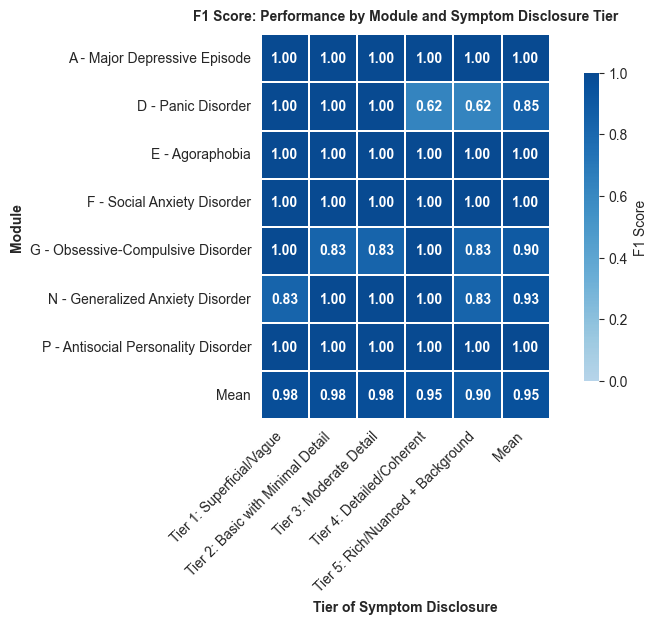


ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Tier of Symptom Disclosure)
                                     Tier 1: Superficial/Vague  \
A - Major Depressive Episode                            1.0000   
D - Panic Disorder                                      1.0000   
E - Agoraphobia                                         1.0000   
F - Social Anxiety Disorder                             1.0000   
G - Obsessive-Compulsive Disorder                       1.0000   
N - Generalized Anxiety Disorder                        0.8333   
P - Antisocial Personality Disorder                     1.0000   

                                     Tier 2: Basic with Minimal Detail  \
A - Major Depressive Episode                                    1.0000   
D - Panic Disorder                                              1.0000   
E - Agoraphobia                                                 1.0000   
F - Social Anxiety Disorder                                     1.0000   
G - Obsessive-Compuls

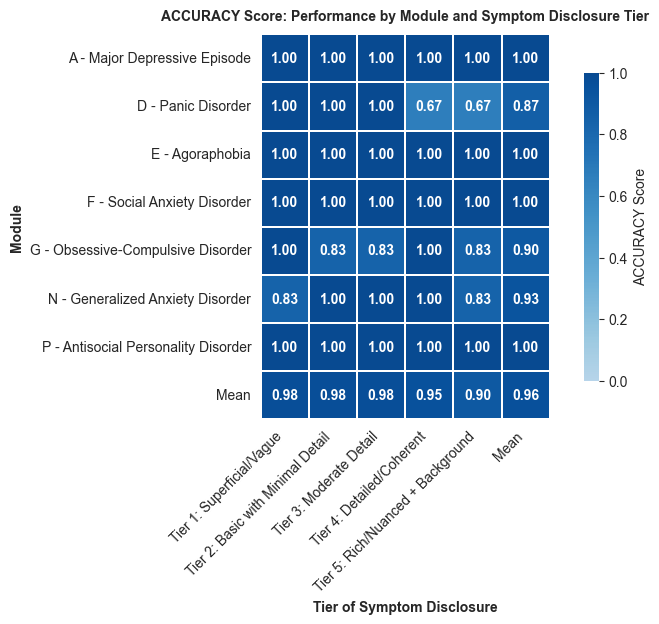


Analysis: Performance by Module and Expected Symptom Direction

F1 SCORE ANALYSIS:
F1 Score Matrix (Module × Expected Symptom Direction)
                                     Negative Symptom Presentation  \
A - Major Depressive Episode                                   1.0   
D - Panic Disorder                                             1.0   
E - Agoraphobia                                                1.0   
F - Social Anxiety Disorder                                    1.0   
G - Obsessive-Compulsive Disorder                              1.0   
N - Generalized Anxiety Disorder                               1.0   
P - Antisocial Personality Disorder                            1.0   

                                     Positive Symptom Presentation  
A - Major Depressive Episode                                1.0000  
D - Panic Disorder                                          0.4231  
E - Agoraphobia                                             1.0000  
F - Social Anxiety Disord

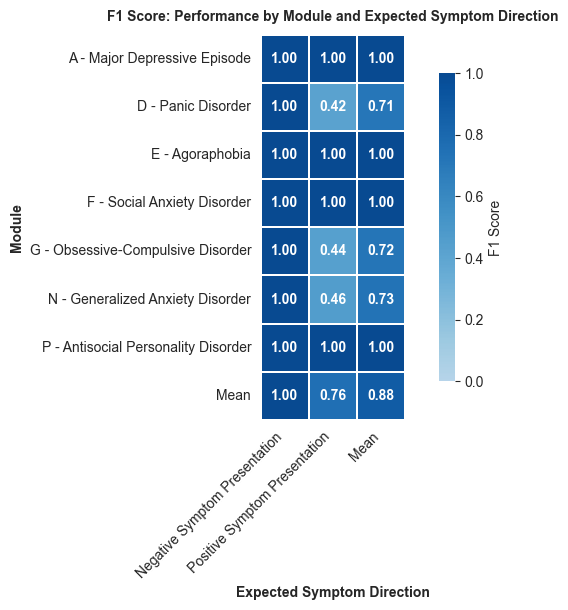


ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Expected Symptom Direction)
                                     Negative Symptom Presentation  \
A - Major Depressive Episode                                   1.0   
D - Panic Disorder                                             1.0   
E - Agoraphobia                                                1.0   
F - Social Anxiety Disorder                                    1.0   
G - Obsessive-Compulsive Disorder                              1.0   
N - Generalized Anxiety Disorder                               1.0   
P - Antisocial Personality Disorder                            1.0   

                                     Positive Symptom Presentation  
A - Major Depressive Episode                                1.0000  
D - Panic Disorder                                          0.7333  
E - Agoraphobia                                             1.0000  
F - Social Anxiety Disorder                                 1.0000  
G - Obsessive-

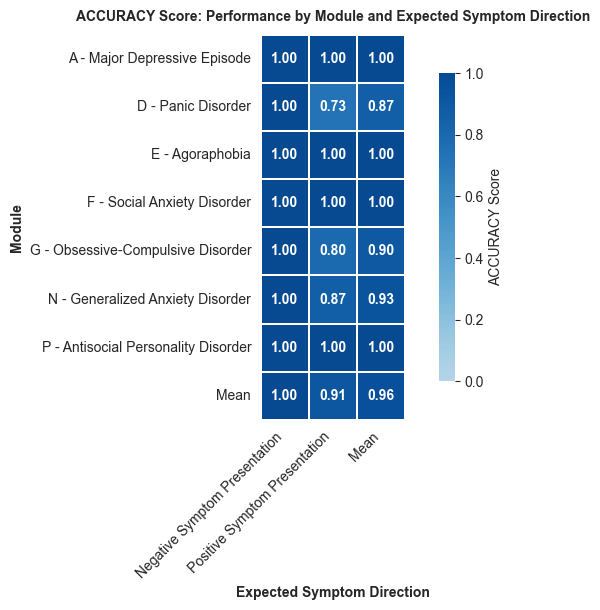


Analysis: Performance by Module and Emotion/Tone Tier

F1 SCORE ANALYSIS:
F1 Score Matrix (Module × Emotion/Tone Tier)
                                     Emotional/Expressive  Flat/Detached  \
A - Major Depressive Episode                       1.0000            1.0   
D - Panic Disorder                                 0.7917            1.0   
E - Agoraphobia                                    1.0000            1.0   
F - Social Anxiety Disorder                        1.0000            1.0   
G - Obsessive-Compulsive Disorder                  0.7917            1.0   
N - Generalized Anxiety Disorder                   0.7917            1.0   
P - Antisocial Personality Disorder                1.0000            1.0   

                                     Neutral/Cooperative  
A - Major Depressive Episode                      1.0000  
D - Panic Disorder                                0.7917  
E - Agoraphobia                                   1.0000  
F - Social Anxiety Disorder        

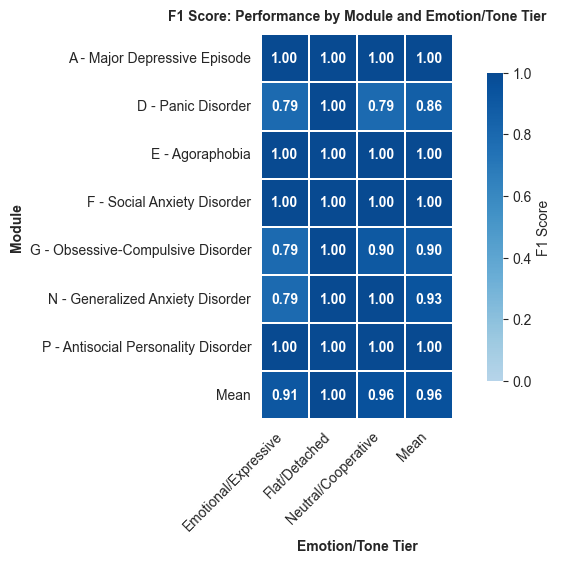


ACCURACY ANALYSIS:
ACCURACY Score Matrix (Module × Emotion/Tone Tier)
                                     Emotional/Expressive  Flat/Detached  \
A - Major Depressive Episode                          1.0            1.0   
D - Panic Disorder                                    0.8            1.0   
E - Agoraphobia                                       1.0            1.0   
F - Social Anxiety Disorder                           1.0            1.0   
G - Obsessive-Compulsive Disorder                     0.8            1.0   
N - Generalized Anxiety Disorder                      0.8            1.0   
P - Antisocial Personality Disorder                   1.0            1.0   

                                     Neutral/Cooperative  
A - Major Depressive Episode                         1.0  
D - Panic Disorder                                   0.8  
E - Agoraphobia                                      1.0  
F - Social Anxiety Disorder                          1.0  
G - Obsessive-Compulsive 

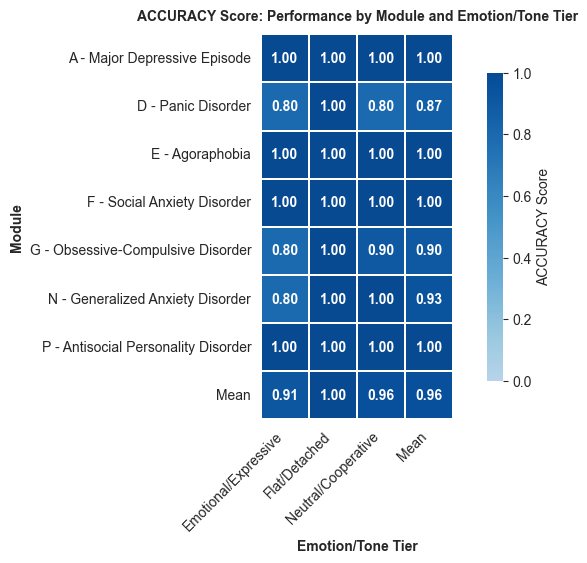

In [15]:


# Run the analysis
if __name__ == "__main__":
    df_final, metrics, f1_matrices, accuracy_matrices = main()